# LLaVA-Style Minimal VLM: Pretrained + Frozen Backbones, Trained Projector

This is the follow-up to `minimal_vlm_from_scratch.ipynb` / `minimal_vlm_more_training.ipynb`. Those notebooks trained a vision encoder *and* a text decoder from scratch, simultaneously, on ~8K images -- which is why the captions were rough despite a clearly-decreasing loss curve.

This notebook builds the actual LLaVA design instead:

| Component | This notebook | The from-scratch notebooks |
|---|---|---|
| Vision encoder | **Pretrained CLIP ViT-B/32, frozen** | `ViTEncoder`, trained from scratch |
| Connector | `nn.Linear` (trained) | `nn.Linear` (trained) |
| Text decoder | **Pretrained SmolLM2-135M, frozen** | Mini causal Transformer, trained from scratch |
| What actually trains | Only the linear projector (~443K params) | Everything (~5-6M params) |

The vision encoder already knows how to see (pretrained via CLIP's 400M-pair contrastive objective) and the language model already knows how to write fluent English (pretrained on a large text corpus). The only thing learned here is the mapping from "what CLIP sees" to "what SmolLM2 expects as input" -- exactly LLaVA's stage-1 feature-alignment pretraining.

**Important asymmetry to keep in mind throughout:** "frozen" means these two models' *weights* never update, but gradients still have to flow *through* them to reach the projector (autograd doesn't know a param is frozen except when deciding whether to store a `.grad` for it -- backpropagation through a frozen layer is exactly as expensive as through a trainable one). So each training step still costs a full forward+backward pass through ~222M frozen parameters, even though only ~443K parameters actually change. That's why this notebook is slower per epoch than the from-scratch ones, even though it should need far fewer epochs to get *some* signal, since it isn't learning "what an edge looks like" or "what English grammar is" from scratch -- only the alignment between the two.


## 1. Setup

In [1]:
import os
import math
import random
import json
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt

from transformers import (
    CLIPVisionModel,
    AutoImageProcessor,
    AutoTokenizer,
    AutoModelForCausalLM,
)

torch.manual_seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)


Using device: mps


## 2. Configuration

Unlike the from-scratch notebooks, there's no `IMG_SIZE`/`PATCH_SIZE` to choose here -- those are properties of whichever pretrained vision checkpoint you load, not free parameters. Both model choices below are small, ungated (no Hugging Face access request / login needed), and permissively licensed, which matters for actually being able to run this locally without friction:

- **Vision encoder**: `openai/clip-vit-base-patch32` -- CLIP's original ViT-B/32, 224x224 images, 49 patches + 1 [CLS] = 50 visual tokens, 768-dim, ~87M params.
- **LLM**: `HuggingFaceTB/SmolLM2-135M` -- a modern, small, Apache-2.0 licensed base LLM, 576-dim, ~135M params, real ~49K-token BPE vocabulary.

Swapping either for a larger sibling (e.g. `SmolLM2-360M`, `Qwen2.5-0.5B`, CLIP ViT-B/16) is a one-line change once this smaller pair is confirmed working end-to-end.

In [ ]:
VISION_MODEL_ID = "openai/clip-vit-base-patch32"
LLM_MODEL_ID = "HuggingFaceTB/SmolLM2-135M"

# --- Data paths (same bridged Flickr8k data as the from-scratch notebooks) ---
IMAGE_DIR = "../data/flickr8k/Images"
CAPTIONS_FILE = "../data/flickr8k/captions.txt"

# --- Training config ---
MAX_TEXT_LEN = 32       # max caption length in tokens, including the appended EOS
BATCH_SIZE = 16
LEARNING_RATE = 1e-3    # only the projector trains, so a higher LR than the from-scratch notebooks is fine
NUM_EPOCHS = 2          # each epoch is much slower here than in the from-scratch notebooks -- see Section 1's note.
                        # ~15-20 min/epoch measured on an M-series Mac (MPS) at BATCH_SIZE=16; bump this up once
                        # you've confirmed the loss is trending down and you're happy to wait longer.


## 3. Load the pretrained, frozen vision encoder

`CLIPVisionModel` is just CLIP's image tower (no text tower, no contrastive head) -- structurally the same shape as the from-scratch `ViTEncoder`: patch embedding, [CLS] token, learned position embeddings, a stack of Transformer blocks. The difference is entirely in the weights: these come from CLIP's actual contrastive pretraining on ~400M image-text pairs, not `nn.init.trunc_normal_`.

`.requires_grad_(False)` freezes every parameter -- the optimizer will never see these, and autograd won't bother building a backward graph through this module at all (its output doesn't require grad, so nothing downstream needs to retain its activations for backprop, unlike the LLM below).

You'll see a long list of "UNEXPECTED" warnings when this loads -- that's expected and harmless: the checkpoint on the Hub is a full CLIP model (vision tower + text tower + projection heads), and `CLIPVisionModel` only pulls out the vision tower, so everything else is reported as unused.

In [3]:
image_processor = AutoImageProcessor.from_pretrained(VISION_MODEL_ID, use_fast=True)
vision_encoder = CLIPVisionModel.from_pretrained(VISION_MODEL_ID, dtype=torch.float32).to(device)
vision_encoder.requires_grad_(False)
vision_encoder.eval()

vision_hidden_size = vision_encoder.config.hidden_size
num_visual_tokens = (vision_encoder.config.image_size // vision_encoder.config.patch_size) ** 2 + 1  # +1 for [CLS]
vision_params = sum(p.numel() for p in vision_encoder.parameters())

print(f"Vision encoder: {VISION_MODEL_ID}")
print(f"  hidden size: {vision_hidden_size}, visual tokens per image: {num_visual_tokens}")
print(f"  frozen parameters: {vision_params:,}")


[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_at

Vision encoder: openai/clip-vit-base-patch32
  hidden size: 768, visual tokens per image: 50
  frozen parameters: 87,456,000


## 4. Load the pretrained, frozen LLM + its tokenizer

This replaces both `SimpleTokenizer` and `TextDecoder` from the from-scratch notebooks in one step. Two things are different in kind, not just degree, from before:

- **The tokenizer already exists and is fixed.** It's SmolLM2's own BPE tokenizer (~49K subword tokens), trained on a huge, general text corpus -- not a ~5,240-word vocabulary built from Flickr8k's own captions. It has no idea Flickr8k exists, and doesn't need to.
- **The language model already knows English.** Before this notebook trains anything, `llm` can already produce fluent (if image-blind) text -- unlike `TextDecoder`, which started as random noise and had to learn grammar and captioning simultaneously.

`SmolLM2-135M` has no dedicated pad token, so we reuse its EOS token as PAD (standard practice for base LLMs used with padded batches -- the `attention_mask` is what actually distinguishes real content from padding, not the token id itself, so this is safe).

In [4]:
tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL_ID, dtype=torch.float32).to(device)
llm.requires_grad_(False)
llm.eval()
llm.config.pad_token_id = tokenizer.pad_token_id

llm_hidden_size = llm.config.hidden_size
llm_vocab_size = llm.config.vocab_size
llm_params = sum(p.numel() for p in llm.parameters())

print(f"LLM: {LLM_MODEL_ID}")
print(f"  hidden size: {llm_hidden_size}, vocab size: {llm_vocab_size:,}")
print(f"  frozen parameters: {llm_params:,}")
print(f"  eos_token_id: {tokenizer.eos_token_id}, pad_token_id: {tokenizer.pad_token_id}")

# Quick sanity check: the frozen LLM should already write plausible English, unconditioned on any image.
_prompt_ids = tokenizer("A photo of", return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    _sample = llm.generate(_prompt_ids, max_new_tokens=15, do_sample=False, pad_token_id=tokenizer.pad_token_id)
print("Frozen LLM, no image, continuing \"A photo of\":", tokenizer.decode(_sample[0], skip_special_tokens=True))


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

LLM: HuggingFaceTB/SmolLM2-135M
  hidden size: 576, vocab size: 49,152
  frozen parameters: 134,515,008
  eos_token_id: 0, pad_token_id: 0
Frozen LLM, no image, continuing "A photo of": A photo of the 1930s.

The 193


## 5. Dataset

Same underlying Flickr8k data (`data/flickr8k/Images` + `data/flickr8k/captions.txt`) as the from-scratch notebooks, but preprocessing changes on both sides:

- **Images** go through `image_processor` (CLIP's own preprocessing recipe: resize, center crop, CLIP-specific normalization stats) instead of the hand-built `torchvision.transforms` pipeline -- the pretrained vision encoder expects images prepared exactly the way it was trained, not our own ImageNet-convention guess.
- **Captions** are tokenized with the LLM's real tokenizer, with `add_special_tokens=False` so we control the sequence by hand (append the real EOS token ourselves, then pad) -- deliberately mirroring how `SimpleTokenizer.encode()` worked before, just backed by a real subword vocabulary now.

`num_workers=0` again, for the same reason as before: on macOS, `DataLoader` workers use the `spawn` start method, and a class defined in a notebook cell (like `CaptionDataset` here) isn't importable by a spawned worker process.

In [5]:
class CaptionDataset(Dataset):
    def __init__(self, image_dir, captions_file, tokenizer, image_processor, max_len):
        self.image_dir = Path(image_dir)
        self.tokenizer = tokenizer
        self.image_processor = image_processor
        self.max_len = max_len
        self.samples = []  # list of (image_filename, caption)

        with open(captions_file, "r", encoding="utf-8") as f:
            lines = f.readlines()
        if lines and "," in lines[0] and lines[0].lower().startswith("image"):
            lines = lines[1:]
        for line in lines:
            line = line.strip()
            if not line:
                continue
            image_name, caption = line.split(",", 1)
            self.samples.append((image_name.strip(), caption.strip()))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_name, caption = self.samples[idx]
        image = Image.open(self.image_dir / image_name).convert("RGB")
        pixel_values = self.image_processor(images=image, return_tensors="pt")["pixel_values"][0]

        # Manual tokenize -> append EOS -> truncate -> pad, the same explicit recipe
        # SimpleTokenizer.encode() used, just backed by a real subword tokenizer now.
        ids = self.tokenizer(caption, add_special_tokens=False)["input_ids"]
        ids = ids[: self.max_len - 1] + [self.tokenizer.eos_token_id]
        attn = [1] * len(ids)
        pad_len = self.max_len - len(ids)
        ids = ids + [self.tokenizer.pad_token_id] * pad_len
        attn = attn + [0] * pad_len

        input_ids = torch.tensor(ids, dtype=torch.long)
        attention_mask = torch.tensor(attn, dtype=torch.long)
        return pixel_values, input_ids, attention_mask


## 6. The LLaVA-style model

`MiniLLaVA` wires the three pieces together the same conceptual way `MiniVLM` did before (vision encoder -> projector -> text model, visual tokens as a prefix), but:

- The vision encoder's forward pass is wrapped in `torch.no_grad()` -- its output doesn't require grad anyway (all its own parameters are frozen and its input, the image, doesn't require grad either), so this is purely a clarity/efficiency choice, not a correctness requirement.
- The LLM's forward pass is **not** wrapped in `no_grad()` -- gradients must flow backward through all of it to reach the projector, even though none of its own weights update. This is the "frozen != free" point from Section 1.
- Loss is computed by handing `labels` straight to the HF model and letting it do its own internal shift-by-one -- we only need to mask out the positions that shouldn't count: the entire visual-token prefix (`-100`) and any padding in the caption (`-100`, via `attention_mask`).
- `train()` is overridden so the two frozen submodules always stay in `.eval()` mode (disabling their dropout, etc.) regardless of whether the outer `MiniLLaVA.train()`/`.eval()` is toggled -- only the projector's mode should ever actually change.

In [6]:
class MiniLLaVA(nn.Module):
    def __init__(self, vision_encoder, llm, tokenizer):
        super().__init__()
        self.vision_encoder = vision_encoder
        self.llm = llm
        self.tokenizer = tokenizer
        self.projector = nn.Linear(vision_encoder.config.hidden_size, llm.config.hidden_size)

    def train(self, mode=True):
        super().train(mode)
        self.vision_encoder.eval()
        self.llm.eval()
        return self

    def _visual_tokens(self, pixel_values):
        with torch.no_grad():
            vision_features = self.vision_encoder(pixel_values=pixel_values).last_hidden_state  # (B, V, D_vision)
        return self.projector(vision_features)  # (B, V, D_llm) -- gradients flow into projector from here

    def forward(self, pixel_values, input_ids, attention_mask):
        visual_tokens = self._visual_tokens(pixel_values)
        text_embeds = self.llm.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([visual_tokens, text_embeds], dim=1)

        V = visual_tokens.shape[1]
        full_attention_mask = torch.cat(
            [torch.ones(pixel_values.shape[0], V, dtype=torch.long, device=pixel_values.device), attention_mask],
            dim=1,
        )

        text_labels = input_ids.clone()
        text_labels[attention_mask == 0] = -100  # ignore padded caption positions
        visual_labels = torch.full((pixel_values.shape[0], V), -100, dtype=torch.long, device=pixel_values.device)
        labels = torch.cat([visual_labels, text_labels], dim=1)

        outputs = self.llm(inputs_embeds=inputs_embeds, attention_mask=full_attention_mask, labels=labels)
        return outputs.logits, outputs.loss

    @torch.no_grad()
    def generate(self, pixel_values, max_new_tokens=32):
        """Greedy caption generation for a batch of images. Uses the LLM's own .generate(),
        which (unlike the from-scratch notebooks' hand-rolled loop) uses real KV-caching internally.
        Because only inputs_embeds is given (no input_ids), the returned sequence is purely the
        generated continuation -- there's no text prompt to strip off."""
        self.eval()
        visual_tokens = self._visual_tokens(pixel_values)
        attention_mask = torch.ones(visual_tokens.shape[:2], dtype=torch.long, device=pixel_values.device)
        return self.llm.generate(
            inputs_embeds=visual_tokens,
            attention_mask=attention_mask,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=self.tokenizer.pad_token_id,
            eos_token_id=self.tokenizer.eos_token_id,
        )


## 7. Quick smoke test (synthetic data)

Same purpose as before: verify shapes and gradient flow on random tensors before touching real data. This time it's also worth printing the trainable-vs-total parameter split -- the headline number for this whole notebook.

In [7]:
_model_test = MiniLLaVA(vision_encoder, llm, tokenizer).to(device)

_total_params = sum(p.numel() for p in _model_test.parameters())
_trainable_params = sum(p.numel() for p in _model_test.parameters() if p.requires_grad)
print(f"Total parameters: {_total_params:,}")
print(f"Trainable parameters (projector only): {_trainable_params:,}  ({100 * _trainable_params / _total_params:.2f}% of total)")

_pixel_values = torch.randn(4, 3, image_processor.crop_size["height"], image_processor.crop_size["width"]).to(device)
_input_ids = torch.randint(0, tokenizer.vocab_size, (4, MAX_TEXT_LEN)).to(device)
_attention_mask = torch.ones(4, MAX_TEXT_LEN, dtype=torch.long).to(device)

_logits, _loss = _model_test(_pixel_values, _input_ids, _attention_mask)
print("logits shape:", _logits.shape)  # expect (4, num_visual_tokens + MAX_TEXT_LEN, llm_vocab_size)
print("loss:", _loss.item())

_loss.backward()
print("projector grad is not None:", _model_test.projector.weight.grad is not None)
print("vision encoder grad (should be None, frozen):", next(_model_test.vision_encoder.parameters()).grad)
print("llm grad (should be None, frozen):", next(_model_test.llm.parameters()).grad)
print("Smoke test passed -- architecture is wired correctly, and only the projector receives gradients.")

del _model_test, _pixel_values, _input_ids, _attention_mask, _logits, _loss


Total parameters: 222,413,952
Trainable parameters (projector only): 442,944  (0.20% of total)
logits shape: torch.Size([4, 82, 49152])
loss: 13.836068153381348
projector grad is not None: True
vision encoder grad (should be None, frozen): None
llm grad (should be None, frozen): None
Smoke test passed -- architecture is wired correctly, and only the projector receives gradients.


## 8. Load real data

Same recipe as the from-scratch notebooks (same `data/flickr8k/` bridge, same 95/5 train/val split with a fixed seed) -- the only change is which dataset/tokenizer classes are involved. There's no vocabulary-building step this time, since the tokenizer is already fixed.

In [8]:
dataset = CaptionDataset(IMAGE_DIR, CAPTIONS_FILE, tokenizer, image_processor, MAX_TEXT_LEN)
print(f"Total (image, caption) pairs: {len(dataset)}")

val_size = max(1, int(0.05 * len(dataset)))
train_size = len(dataset) - val_size
train_set, val_set = torch.utils.data.random_split(
    dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"train batches: {len(train_loader)}  val batches: {len(val_loader)}")


Total (image, caption) pairs: 40455
train batches: 2402  val batches: 127


## 9. Instantiate the model and optimizer

The critical difference from the from-scratch notebooks: the optimizer is only ever given `model.projector.parameters()`. The vision encoder and LLM parameters are frozen (`requires_grad=False`), so even if we passed `model.parameters()` here, the frozen ones would never accumulate gradients or update -- but being explicit about optimizing only the projector makes the intent unambiguous and keeps the optimizer's internal state (Adam's moment buffers) small.

In [9]:
model = MiniLLaVA(vision_encoder, llm, tokenizer).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters (projector only): {trainable_params:,}  ({100 * trainable_params / total_params:.2f}% of total)")

optimizer = torch.optim.AdamW(model.projector.parameters(), lr=LEARNING_RATE)


Total parameters: 222,413,952
Trainable parameters (projector only): 442,944  (0.20% of total)


## 10. Training loop

Structurally identical to the from-scratch notebooks' `run_epoch` -- teacher forcing, cross-entropy loss, gradient clipping -- except the loss now comes back from the HF model itself (`model(...)` returns `(logits, loss)` rather than raw logits we'd have to feed into our own `loss_fn`), and only the projector's gradients ever get clipped/stepped.

In [10]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, total_tokens = 0.0, 0
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for pixel_values, input_ids, attention_mask in loader:
            pixel_values = pixel_values.to(device)
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)

            _, loss = model(pixel_values, input_ids, attention_mask)

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.projector.parameters(), max_norm=1.0)
                optimizer.step()

            n_tok = attention_mask.sum().item()
            total_loss += loss.item() * n_tok
            total_tokens += n_tok
    return total_loss / max(total_tokens, 1)


history = {"train_loss": [], "val_loss": []}
for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = run_epoch(train_loader, train=True)
    val_loss = run_epoch(val_loader, train=False)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch}/{NUM_EPOCHS} -- train_loss: {train_loss:.4f}  val_loss: {val_loss:.4f}")


Epoch 1/2 -- train_loss: 2.6625  val_loss: 2.5163
Epoch 2/2 -- train_loss: 2.4573  val_loss: 2.4525


## 11. Plot the training curve

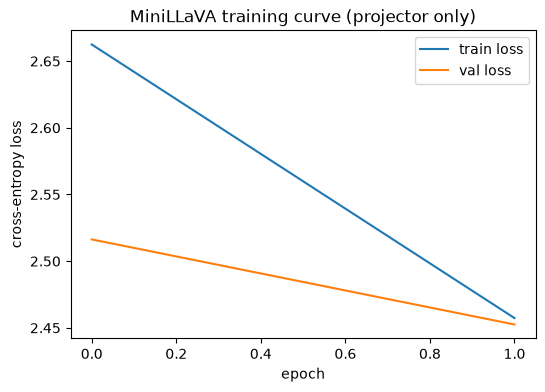

In [11]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train loss")
plt.plot(history["val_loss"], label="val loss")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("MiniLLaVA training curve (projector only)")
plt.legend()
plt.show()


## 12. Inference: generate a caption for a sample image

Same idea as the from-scratch notebooks' Section 11: show the freely-generated caption next to the ground truth, plus the teacher-forced loss/perplexity for that specific example (see the earlier discussion of what that number does and doesn't tell you). The random-baseline reference point is different here, though -- `ln(vocab_size) = ln(49152) ≈ 10.8`, versus `ln(5240) ≈ 8.56` for the from-scratch notebooks' smaller word-level vocabulary.

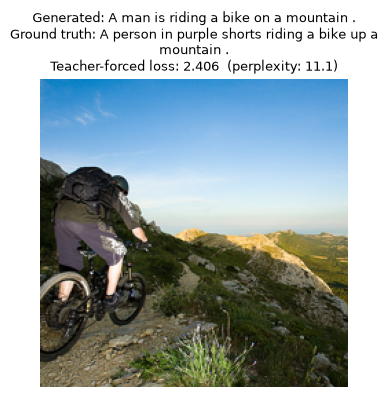

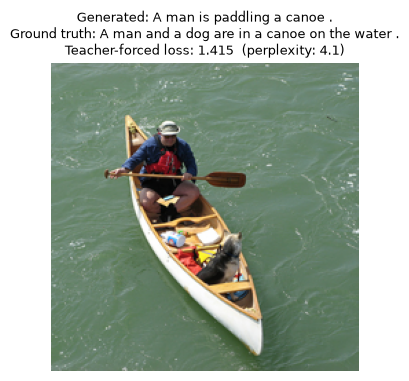

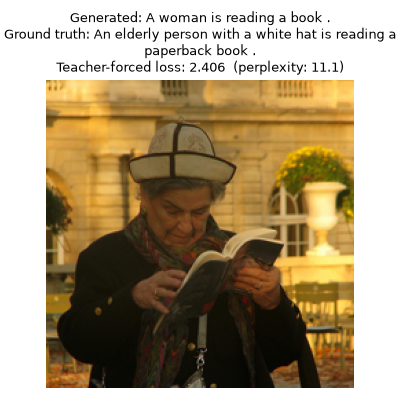

In [12]:
@torch.no_grad()
def caption_loss(pixel_values, input_ids, attention_mask):
    model.eval()
    _, loss = model(pixel_values.unsqueeze(0).to(device), input_ids.unsqueeze(0).to(device), attention_mask.unsqueeze(0).to(device))
    return loss.item()


def show_prediction(dataset_obj, idx):
    pixel_values, input_ids, attention_mask = dataset_obj[idx]
    generated_ids = model.generate(pixel_values.unsqueeze(0).to(device), max_new_tokens=MAX_TEXT_LEN)
    caption = tokenizer.decode(generated_ids[0], skip_special_tokens=True)
    ground_truth = tokenizer.decode(input_ids, skip_special_tokens=True)
    loss = caption_loss(pixel_values, input_ids, attention_mask)
    perplexity = math.exp(loss)

    # Unnormalize using CLIP's own mean/std (not ImageNet's -- a different pretrained convention)
    mean = torch.tensor(image_processor.image_mean).view(3, 1, 1)
    std = torch.tensor(image_processor.image_std).view(3, 1, 1)
    img_display = (pixel_values * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

    plt.figure(figsize=(4, 4))
    plt.imshow(img_display)
    plt.axis("off")
    plt.title(
        f"Generated: {caption}\nGround truth: {ground_truth}\n"
        f"Teacher-forced loss: {loss:.3f}  (perplexity: {perplexity:.1f})",
        fontsize=9, wrap=True,
    )
    plt.show()


for i in random.sample(range(len(val_set)), min(3, len(val_set))):
    show_prediction(val_set.dataset, val_set.indices[i])


## 13. Quantitative comparison: fixed-set BLEU-4 (via `eval_utils.py`)

Teacher-forced loss/perplexity (Section 12) has two problems as a way to score this notebook against the from-scratch one, and against the Stage 2 LoRA notebook later: it's computed against a different vocabulary (a different random-guessing floor -- `ln(49152) ≈ 10.8` here vs. `ln(5240) ≈ 8.56` for the from-scratch notebook), and for an already-fluent frozen LLM it's dominated by the LLM's own language prior rather than by whether the caption is actually grounded in the image -- see `eval_utils.py`'s module docstring for the full argument.

`evaluate_fixed_set` instead runs *free generation* (the model's own greedy captions, not the teacher-forced reference) on the same fixed set of 10 validation images every notebook uses, and scores the results with corpus BLEU-4 against Flickr8k's real reference captions for each image. BLEU-4 doesn't care about a model's internal vocabulary size, so it's the number that's actually fair to compare across the from-scratch, Stage 1, and Stage 2 notebooks.

In [13]:
import sys
sys.path.insert(0, ".")  # adjust if eval_utils.py lives elsewhere
from eval_utils import evaluate_fixed_set, build_reference_lookup

reference_lookup = build_reference_lookup(CAPTIONS_FILE)

def generate_and_decode(val_set, idx):
    pixel_values, _input_ids, _attention_mask = val_set.dataset[val_set.indices[idx]]
    generated_ids = model.generate(pixel_values.unsqueeze(0).to(device), max_new_tokens=MAX_TEXT_LEN)
    return tokenizer.decode(generated_ids[0], skip_special_tokens=True)

stage1_results = evaluate_fixed_set(val_set, generate_and_decode, reference_lookup)
print(f"\nStage 1 (projector only) corpus BLEU-4 on fixed set: {stage1_results['bleu4']:.4f}")


Corpus BLEU-4 over 10 fixed images: 0.2049

  [1459032057_97e73ed6ab.jpg]
    generated: A little girl is eating a cake .
    reference: A girl in a striped shirt holds a bun to her mouth .
  [1178705300_c224d9a4f1.jpg]
    generated: A dog jumps out of a pool .
    reference: a brown dog jumping into a pool after a bloe ball .
  [2206594874_5e0087c6b7.jpg]
    generated: A man and a boy are sitting on a bench .
    reference: A couple sits at a cramped table in a busy restaurant .
  [3376809186_4e26d880b7.jpg]
    generated: A group of people are walking on a beach .
    reference: A group of people are in the water .
  [783994497_4f6885454d.jpg]
    generated: A man is holding a bag of money .
    reference: A group of people are getting fountain drinks at a convenience store .
  [2455528149_6c3477fd33.jpg]
    generated: A man is standing in front of a group of people .
    reference: A delivery man is passing by two people at an art gallery .
  [1294578091_2ad02fea91.jpg]
    gener

In [15]:
import sys
sys.path.insert(0, ".")
import importlib
import eval_utils
importlib.reload(eval_utils)
from eval_utils import evaluate_fixed_set, build_reference_lookup, save_result

reference_lookup = build_reference_lookup(CAPTIONS_FILE)

def generate_and_decode(val_set, idx):
    pixel_values, _input_ids, _attention_mask = val_set.dataset[val_set.indices[idx]]
    generated_ids = model.generate(pixel_values.unsqueeze(0).to(device), max_new_tokens=MAX_TEXT_LEN)
    return tokenizer.decode(generated_ids[0], skip_special_tokens=True)

stage1_results = evaluate_fixed_set(val_set, generate_and_decode, reference_lookup)
print(f"\nStage 1 (projector only) corpus BLEU-4 on fixed set: {stage1_results['bleu4']:.4f}")
save_result("Stage 1 (LLaVA, projector only)", stage1_results)


Corpus BLEU-4 over 10 fixed images: 0.2049

  [1459032057_97e73ed6ab.jpg]
    generated: A little girl is eating a cake .
    reference: A girl in a striped shirt holds a bun to her mouth .
  [1178705300_c224d9a4f1.jpg]
    generated: A dog jumps out of a pool .
    reference: a brown dog jumping into a pool after a bloe ball .
  [2206594874_5e0087c6b7.jpg]
    generated: A man and a boy are sitting on a bench .
    reference: A couple sits at a cramped table in a busy restaurant .
  [3376809186_4e26d880b7.jpg]
    generated: A group of people are walking on a beach .
    reference: A group of people are in the water .
  [783994497_4f6885454d.jpg]
    generated: A man is holding a bag of money .
    reference: A group of people are getting fountain drinks at a convenience store .
  [2455528149_6c3477fd33.jpg]
    generated: A man is standing in front of a group of people .
    reference: A delivery man is passing by two people at an art gallery .
  [1294578091_2ad02fea91.jpg]
    gener

## 14. Save the projector for Stage 2

`minimal_vlm_llava_stage2_lora.ipynb` warm-starts its projector from this checkpoint, so the LLM's LoRA adapters adapt around an already-roughly-aligned connector rather than around random noise -- see that notebook's own opening notes for why this ordering mirrors LLaVA's actual two-stage recipe.

In [14]:
torch.save(model.projector.state_dict(), "stage1_projector.pt")
print("Saved projector weights to stage1_projector.pt")


Saved projector weights to stage1_projector.pt


## 15. Notes for the reading log / report

- **What changed vs. the from-scratch notebooks:** the vision encoder and text decoder are no longer learned -- they're pretrained, frozen models (`openai/clip-vit-base-patch32`, `HuggingFaceTB/SmolLM2-135M`). The only thing trained here is the linear projector: **~443K trainable parameters out of ~222M total (~0.2%)**. This is exactly LLaVA's stage-1 feature-alignment pretraining, at small scale.
- **Why captions might look different in kind, not just in degree, from the from-scratch runs:** the LLM already writes fluent English regardless of the image (see the frozen-LLM sanity check in Section 4) -- so captions here should read as grammatical, coherent sentences from very early in training, even if they're not yet accurately *about* the image. The from-scratch notebooks' failure mode was "learning both grammar and grounding at once, on very little data"; this notebook's failure mode, if undertrained, looks more like "grammatically fine but visually generic/ungrounded" -- a good thing to explicitly compare against the from-scratch captions you already generated.
- **Why this is slower per epoch despite training far fewer parameters:** frozen doesn't mean free -- every step still runs a full forward+backward pass through ~222M parameters to get a gradient into the 443K-param projector (see Section 1). Fewer epochs are needed to see a trend, but each one costs more wall-clock time.
- **The honest cross-check between the from-scratch and LLaVA-style runs:** compare `ln(vocab_size)` as the random-guessing floor for each (`8.56` for the ~5,240-word custom vocab vs. `10.8` for SmolLM2's ~49K-token vocab) against each model's actual val_loss, rather than comparing raw val_loss numbers directly -- the two notebooks are scored against different vocabularies, so the raw numbers alone aren't directly comparable.
- **Natural next step if you want to go further:** unfreeze the projector-trained model's LLM (or the top few layers of it) for a second fine-tuning stage, mirroring LLaVA's stage-2 -- exactly the kind of experiment this notebook's structure makes easy to try, by changing which parameters get passed to the optimizer.
